# Fabio Banyu Cyto — Gaji Rp3 Juta, Kapan Bisa Beli Rumah?

Studi skenario Lampung, snapshot **30 Oktober 2026**. Notebook berisi kode model lengkap yang telah dijalankan. Ekstrak ZIP dan buka dari folder yang sama dengan data. Data observasi, asumsi, dan hasil simulasi disimpan terpisah. Baca reports/laporan.html dan docs/DATA_DICTIONARY.md untuk audit dan batas interpretasi.

Pertanyaan: kapan dana awal terkumpul, kapan cicilan memenuhi anggaran, dan kapan rumah dijadwalkan lunas? Profil contoh berusia 23 tahun dan bergaji bersih Rp3 juta. Peluang Monte Carlo berlaku dalam distribusi asumsi, bukan peluang persetujuan bank atau peluang seluruh pekerja.

In [1]:
from pathlib import Path
import pandas as pd, json
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
assert (ROOT/'data'/'processed').exists(), 'Ekstrak ZIP dan jalankan notebook dari folder mikfes_lampung'
manifest = json.loads((ROOT/'data/source_manifest.json').read_text(encoding='utf-8'))
display(pd.DataFrame(manifest)[['source_id','status','bytes','published_date','reference_period']])

,source_id,status,bytes,published_date,reference_period
0,bps_pengeluaran,downloaded_no_table_data,97609.0,NaN,NaN
1,bps_upah,downloaded_verified_content,141898.0,NaN,February and August 2025; annual cells missing
2,bps_inflasi_lampung,downloaded_verified_content,112876.0,NaN,January-September 2026
3,bi_shpr_2026q2,downloaded_verified_content,664287.0,2026-08-07,2026Q2; historical annex 2021Q1-2026Q2 nationa...
4,sikumbang_menara,downloaded_verified_content,17139.0,NaN,Snapshot 2026-10-30
5,tapera_flpp,downloaded_verified_content,246737.0,NaN,NaN
6,tapera_brosur,downloaded_verified_content,3569997.0,NaN,Brochure in 2025/09 URL path; exact publicatio...
7,mandiri_flpp,downloaded_verified_content,144622.0,NaN,NaN
8,pkp_tenor,downloaded_verified_content,101996.0,NaN,NaN
9,bi_report_page,downloaded_verified_content,646462.0,2026-08-07,2026Q2; historical annex 2021Q1-2026Q2 nationa...


## 1. Observasi dan EDA

Upah dan konsumsi merupakan agregat survei. Gaji Rp3 juta dan biaya Rp2,1 juta adalah profil asumsi. Dua harga dari satu proyek tidak membentuk distribusi harga Lampung. Nilai kosong tidak diubah menjadi nol.

In [2]:
upah = pd.read_csv(ROOT/'data/processed/bps_upah_2025.csv')
pengeluaran = pd.read_csv(ROOT/'data/processed/bps_pengeluaran_lampung_2025.csv')
harga = pd.read_csv(ROOT/'data/processed/sikumbang_harga_lampung.csv')
display(upah[(upah.province=='LAMPUNG') & (upah.sector=='Total')])
display(pengeluaran[pengeluaran.commodity.str.startswith('Jumlah')])
display(harga)
display(pd.read_csv(ROOT/'data/processed/bps_pengeluaran_history.csv'))
print('Missing wage cells:', upah.wage_idr_month.isna().sum(), '/', len(upah))

Missing wage cells: 798 / 2106


,province_code,province,year,period,sector,wage_idr_month,missing,source_id,source_key,data_class
429,1800,LAMPUNG,2025,Februari,Total,2320932.0,False,bps_upah,180024752085125189,observed_aggregate
430,1800,LAMPUNG,2025,Agustus,Total,2520619.0,False,bps_upah,180024752085125190,observed_aggregate
431,1800,LAMPUNG,2025,Tahunan,Total,NaN,True,bps_upah,180024752085125191,observed_aggregate


,province,period,commodity,area,expenditure_idr_capita_month,raw_value,data_class,source_id
45,Lampung,2025-03,Jumlah makanan,Kota,734064.0,734.064,observed_aggregate,bps_konsumsi_komoditas
46,Lampung,2025-03,Jumlah makanan,Desa,626698.0,626.698,observed_aggregate,bps_konsumsi_komoditas
47,Lampung,2025-03,Jumlah makanan,Kota+Desa,663740.0,663.740,observed_aggregate,bps_konsumsi_komoditas
69,Lampung,2025-03,Jumlah bukan makanan,Kota,760502.0,760.502,observed_aggregate,bps_konsumsi_komoditas
70,Lampung,2025-03,Jumlah bukan makanan,Desa,478619.0,478.619,observed_aggregate,bps_konsumsi_komoditas
71,Lampung,2025-03,Jumlah bukan makanan,Kota+Desa,575873.0,575.873,observed_aggregate,bps_konsumsi_komoditas
72,Lampung,2025-03,Jumlah/Total,Kota,1494565.0,1.494.565,observed_aggregate,bps_konsumsi_komoditas
73,Lampung,2025-03,Jumlah/Total,Desa,1105317.0,1.105.317,observed_aggregate,bps_konsumsi_komoditas
74,Lampung,2025-03,Jumlah/Total,Kota+Desa,1239613.0,1.239.613,observed_aggregate,bps_konsumsi_komoditas


,project_id,project,province,regency,district,village,type,segment,price_idr,building_m2,land_m2,snapshot_date,listing_updated_date,source_id,data_class
0,KLA0610282026T001,Menara Siger Residence,Lampung,Lampung Selatan,Kalianda,Wai Lubuk,36/80,subsidi,166000000,36,80,2026-10-30,NaN,sikumbang_menara,observed_asking_price
1,KLA0610282026T001,Menara Siger Residence,Lampung,Lampung Selatan,Kalianda,Wai Lubuk,50/90,komersil,350000000,50,90,2026-10-30,NaN,sikumbang_menara,observed_asking_price


,province,year,total_idr_capita_month,source_id,locator,data_class
0,Lampung,2021,1030579,bps_lampung_2026_pdf,PDF page727; printed679; Figure11.1,observed_aggregate
1,Lampung,2022,1074987,bps_lampung_2026_pdf,PDF page727; printed679; Figure11.1,observed_aggregate
2,Lampung,2023,1203017,bps_lampung_2026_pdf,PDF page727; printed679; Figure11.1,observed_aggregate
3,Lampung,2024,1201473,bps_lampung_2026_pdf,PDF page727; printed679; Figure11.1,observed_aggregate
4,Lampung,2025,1239613,bps_lampung_2026_pdf,PDF page727; printed679; Figure11.1,observed_aggregate


## 2. Model dan asumsi yang dapat diubah

Kode berikut memuat model lengkap seperti model.py, dengan jalur data disesuaikan untuk notebook. Anuitas 5% nominal adalah pilihan model. Halaman Tapera menulis flat; alternatif flat juga diuji. Pertumbuhan dan distribusi masa depan adalah asumsi, bukan estimasi otomatis BPS/BI. Batas usia lunas 55 tahun menggunakan contoh ketentuan Mandiri dan tidak digeneralisasi ke semua bank. Harga awal dibaca dari CSV SiKumbang.

In [3]:
"""Fabio Banyu Cyto: financial scenario model. All future distributions are assumptions.
Run from notebook, or: python model.py. Monetary units: nominal IDR.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT=Path.cwd()
DATA=ROOT/'data'/'processed'; RES=ROOT/'results'; FIG=ROOT/'figures'
for p in (RES,FIG): p.mkdir(exist_ok=True)
_houses=pd.read_csv(DATA/'sikumbang_harga_lampung.csv')
PRICES={seg:float(_houses.loc[_houses.segment==src,'price_idr'].iloc[0]) for seg,src in [('subsidy','subsidi'),('commercial','komersil')]}
BASE=dict(wage=3_000_000.,living=2_100_000.,rent=600_000.,initial_savings=0.,
          age=23.,horizon_years=40,loan_years=20,max_maturity_age=55.,
          wage_growth=.04,cost_growth=.03,commercial_growth=.03,subsidy_growth=0.,
          saving_return=.03,dsr=.30,buffer=.10,emergency_months=6.,maintenance=.005,
          subsidy_dp=.01,commercial_dp=.20,subsidy_fees=.03,commercial_fees=.05,
          subsidy_rate=.05,commercial_rate=.10,commercial_stress_rate=.13,
          subsidy_income_cap=8_500_000.,seed=20261030,n_paths=10000,
          wage_sd=.06,cost_sd=.015,house_sd=.04,return_sd=.01,commercial_rate_sd=.015,
          subsidy_jump_probability=.20,subsidy_jump_size=.05)
BASE['subsidy_amortization']='annuity'

def pmt(principal,annual_rate,months):
    p,r,n=np.broadcast_arrays(np.asarray(principal,float),np.asarray(annual_rate,float)/12,np.asarray(months,float))
    safe=np.where(r==0,1.,r)
    return np.where(r==0,p/n,p*safe/(1-(1+safe)**(-n)))

def draw_paths(c,n,stochastic=False,policy_jumps=False):
    """Annual correlated shocks; smooth compounding within each year.
    Wage/cost correlation .30, cost/house .25, wage/house .20. Others zero.
    Returns and interest rates independent of these, not an estimated system.
    """
    y=c['horizon_years']; rng=np.random.default_rng(c['seed'])
    corr=np.array([[1,.30,.20,0],[.30,1,.25,0],[.20,.25,1,0],[0,0,0,1.]])
    means=np.array([c['wage_growth'],c['cost_growth'],c['commercial_growth'],c['saving_return']])
    sd=np.array([c['wage_sd'],c['cost_sd'],c['house_sd'],c['return_sd']]) if stochastic else np.zeros(4)
    z=rng.standard_normal((n,y,4))@np.linalg.cholesky(corr).T
    growth=np.clip(means+z*sd,[-.20,-.02,-.10,0],[.25,.15,.20,.10])
    def levels(start,g):
        annual=np.concatenate([np.ones((n,1)),np.cumprod(1+g,axis=1)],axis=1)
        m=np.arange(y*12+1); a=np.minimum(m//12,y-1); f=(m-a*12)/12
        return start*annual[:,a]*(1+g[:,a])**f
    rates=np.clip(rng.normal(c['commercial_rate'],c['commercial_rate_sd'] if stochastic else 0,(n,y)),.06,.15)
    subg=np.full((n,y),c['subsidy_growth'])
    if stochastic and policy_jumps:
        subg=np.where(rng.random((n,y))<c['subsidy_jump_probability'],c['subsidy_jump_size'],0.)
    # In static tests the configured rate is retained even outside stochastic bounds.
    if not stochastic: rates[:]=c['commercial_rate']
    return dict(wage=levels(c['wage'],growth[:,:,0]),living=levels(c['living'],growth[:,:,1]),
        rent=levels(c['rent'],growth[:,:,1]),commercial=levels(PRICES['commercial'],growth[:,:,2]),
        subsidy=levels(PRICES['subsidy'],subg),returns=np.repeat(growth[:,:,3],12,axis=1),rates=rates)

def simulate(c,paths,segment,method='kpr',save_trace=False):
    """First-passage financial eligibility; not credit approval.
    Independent counterfactual for every segment/method, never buy twice.
    Purchase at month-end after saving. Loan payments start next month.
    Extra available savings above costs+emergency go into down payment.
    """
    w,lv,rent,h=[paths[k] for k in ['wage','living','rent',segment]]
    n,T=w.shape; months=T-1; term=int(c['loan_years']*12)
    fee=c[segment+'_fees']; min_dp=c[segment+'_dp']
    bal=np.full(n,c['initial_savings']); first=np.full(n,np.nan); dp_ready=np.full(n,np.nan)
    dp_actual=np.full(n,np.nan); loan=np.zeros(n); payment=np.zeros(n); purchase_price=np.zeros(n)
    rate_initial=np.zeros(n); purchase_cost=np.zeros(n); completed=np.zeros(n,bool); original_principal=np.zeros(n)
    flat=(segment=='subsidy' and c['subsidy_amortization']=='flat')
    liquidity_fail=np.zeros(n,bool); budget_breach=np.zeros(n,bool); first_trace=[]
    for t in range(months+1):
        if t:
            active=np.isfinite(first)&(t>first)&(t<=first+term)&(method=='kpr')
            waiting=~np.isfinite(first)
            ret=(1+paths['returns'][:,t-1])**(1/12)-1
            bal+=np.maximum(bal,0)*ret  # deficits persist, no invented interest on debt
            bal[waiting]+=w[waiting,t]-lv[waiting,t]
            if method=='kpr':
                if segment=='commercial':
                    # 3 years fixed; reprice every 12 months thereafter.
                    reprice=active&((t-first-1)>=36)&(((t-first-1)%12)==0)
                    if reprice.any():
                        rr=paths['rates'][:,min((t-1)//12,c['horizon_years']-1)]
                        rate_initial[reprice]=rr[reprice]
                        remain=term-(t-first[reprice]-1)
                        payment[reprice]=pmt(loan[reprice],rr[reprice],remain)
                own_cost=lv[:,t]-rent[:,t]+c['maintenance']*purchase_price/12*(lv[:,t]/np.maximum(purchase_cost,1))
                cashflow=w[:,t]-own_cost-payment
                bal[active]+=cashflow[active]
                liquidity_fail|=active&(bal<0)
                budget_breach|=active&((payment>c['dsr']*w[:,t])|(cashflow<c['buffer']*w[:,t]))
                if flat: loan[active]=np.maximum(0,loan[active]-original_principal[active]/term)
                else: loan[active]=np.maximum(0,loan[active]*(1+rate_initial[active]/12)-payment[active])
                ended=active&(t==first+term); completed|=ended&(loan<1.)&(~liquidity_fail)
        waiting=~np.isfinite(first)
        reserve=c['emergency_months']*lv[:,t]
        ready=(bal>=h[:,t]*(min_dp+fee)+reserve)
        dp_ready[np.isnan(dp_ready)&ready]=t
        if method=='cash':
            qualify=waiting&(bal>=h[:,t]*(1+fee)+reserve)
            purchase_price[qualify]=h[qualify,t]
            first[qualify]=t; bal[qualify]-=h[qualify,t]*(1+fee)
        else:
            upkeep=c['maintenance']*h[:,t]/12
            capacity=np.maximum(0,np.minimum(c['dsr']*w[:,t],w[:,t]-(lv[:,t]-rent[:,t])-upkeep-c['buffer']*w[:,t]))
            extra_dp=np.minimum(h[:,t],np.maximum(0,bal-fee*h[:,t]-reserve))
            principal=np.maximum(0,h[:,t]-extra_dp)
            rr=c['subsidy_rate'] if segment=='subsidy' else c['commercial_rate']
            stress=rr if segment=='subsidy' else max(rr,c['commercial_stress_rate'])
            required=principal/term+principal*stress/12 if flat else pmt(principal,stress,term)
            eligible_age=c['age']+t/12+c['loan_years']<=c['max_maturity_age']+1e-9
            eligible_income=w[:,t]<=c['subsidy_income_cap'] if segment=='subsidy' else np.ones(n,bool)
            qualify=waiting&ready&(required<=capacity)&eligible_age&eligible_income
            first[qualify]=t; dp_actual[qualify]=extra_dp[qualify]; purchase_price[qualify]=h[qualify,t]
            purchase_cost[qualify]=lv[qualify,t]
            loan[qualify]=principal[qualify]; original_principal[qualify]=principal[qualify]; rate_initial[qualify]=rr
            payment[qualify]=principal[qualify]/term+principal[qualify]*rr/12 if flat else pmt(principal[qualify],rr,term)
            bal[qualify]-=extra_dp[qualify]+fee*h[qualify,t]
        if save_trace:
            first_trace.append(dict(month=t,year=t/12,age=c['age']+t/12,wage=w[0,t],living=lv[0,t],house_price=h[0,t],balance=bal[0],purchase_month=first[0],loan_balance=loan[0],payment=payment[0]))
    out=pd.DataFrame(dict(path_id=np.arange(n),segment=segment,method=method,
        dp_ready_month=dp_ready,purchase_month=first,purchase_age=c['age']+first/12,
        extra_down_payment_idr=dp_actual,purchase_price_idr=np.where(np.isfinite(first),purchase_price,np.nan),
        liquidity_failure_after_entry=np.where(np.isfinite(first),liquidity_fail,False),
        budget_breach_after_entry=np.where(np.isfinite(first),budget_breach,False),
        loan_completed_without_liquidity_failure=completed,
        scheduled_payoff_age=np.where(np.isfinite(first)&(method=='kpr'),c['age']+first/12+c['loan_years'],np.nan)))
    return out,pd.DataFrame(first_trace)

def summarize(df,c,label):
    rows=[]
    for (seg,method),g in df.groupby(['segment','method']):
        hit=g.purchase_month.notna(); times=g.loc[hit,'purchase_month']/12
        row=dict(experiment=label,segment=seg,method=method,n_paths=len(g),p_success_40y=hit.mean(),
                 p_not_reached_40y=1-hit.mean(),median_years_success_only=times.median(),
                 p10_years_success_only=times.quantile(.1),p90_years_success_only=times.quantile(.9),
                 median_years_all_paths=(times.quantile(.5/hit.mean()) if hit.mean()>=.5 else np.nan),
                 p_entry_and_no_liquidity_failure=(hit&~g.liquidity_failure_after_entry).mean(),
                 p_liquidity_failure_conditional_on_entry=(g.loc[hit,'liquidity_failure_after_entry'].mean() if hit.any() else np.nan),
                 p_budget_breach_conditional_on_entry=(g.loc[hit,'budget_breach_after_entry'].mean() if hit.any() else np.nan))
        for age in [30,35,40]: row[f'p_by_age_{age}']=(g.purchase_age<=age).mean()
        for age in [30,35,40]: row[f'mc_se_by_age_{age}']=np.sqrt(row[f'p_by_age_{age}']*(1-row[f'p_by_age_{age}'])/len(g))
        rows.append(row)
    return pd.DataFrame(rows)

def run_suite(c=BASE,n=None,stochastic=False,policy_jumps=False,trace=False):
    p=draw_paths(c,n or (c['n_paths'] if stochastic else 1),stochastic,policy_jumps)
    results=[]; traces=[]
    for seg in ['subsidy','commercial']:
        for method in ['cash','kpr']:
            out,tr=simulate(c,p,seg,method,trace); results.append(out)
            if len(tr): tr['segment']=seg; tr['method']=method; traces.append(tr)
    return pd.concat(results,ignore_index=True),pd.concat(traces,ignore_index=True) if traces else pd.DataFrame()

def validation():
    checks=[]
    def test(name,condition,detail=''):
        assert condition,(name,detail); checks.append(dict(check=name,status='PASS',detail=detail))
    test('PMT 166m minus 1% DP,5%,240 months',abs(float(pmt(164340000,.05,240))-1084570.56)<1)
    test('Zero interest PMT',float(pmt(1200000,0,12))==100000)
    pay=float(pmt(164340000,.05,240)); bal=164340000.
    for _ in range(240): bal=bal*(1+.05/12)-pay
    test('Amortization balance after240',abs(bal)<.01)
    test('Longer tenor lowers payment',pmt(100e6,.05,480)<pmt(100e6,.05,240))
    test('Higher rate raises payment',pmt(100e6,.13,240)>pmt(100e6,.10,240))
    c={**BASE,'wage_growth':0.,'cost_growth':0.,'commercial_growth':0.,'saving_return':0.,'subsidy_fees':0.,'commercial_fees':0.,'emergency_months':0.}
    df,_=run_suite(c)
    test('Static cash subsidiary ceiling months',df.query("segment=='subsidy' and method=='cash'").purchase_month.iloc[0]==185)
    test('Static cash commercial ceiling months',df.query("segment=='commercial' and method=='cash'").purchase_month.iloc[0]==389)
    aa,_=run_suite(BASE,n=1); bb,_=run_suite(BASE,n=10)
    test('Identical deterministic replicated paths',all(bb.groupby(['segment','method']).purchase_month.nunique(dropna=False)==1))
    aa,_=run_suite(BASE,n=12,stochastic=True); bb,_=run_suite(BASE,n=12,stochastic=True)
    test('Seed reproducibility',aa.equals(bb))
    c={**BASE,'wage':1_000_000.,'wage_growth':0.,'cost_growth':0.}
    fail,_=run_suite(c,n=1)
    test('Negative saving never creates eligibility',fail.purchase_month.isna().all())
    c={**BASE,'initial_savings':1e9}; immediate,_=run_suite(c,n=1)
    test('Initial assets permit t0 cash',immediate.query("method=='cash'").purchase_month.eq(0).all())
    for filename in ['bi_ihpr.csv','sikumbang_harga_lampung.csv','bps_upah_2025.csv']:
        data=pd.read_csv(DATA/filename); test('No duplicated rows '+filename,not data.duplicated().any())
    data=pd.read_csv(DATA/'bps_pengeluaran_lampung_2025.csv')
    totals=data[data.commodity.str.startswith('Jumlah')].pivot(index='area',columns='commodity',values='expenditure_idr_capita_month')
    test('BPS food+nonfood vs total rounding <=1 IDR',((totals['Jumlah makanan']+totals['Jumlah bukan makanan']-totals['Jumlah/Total']).abs()<=1).all())
    # Eligibility boundary and lower expenses should not delay first purchase in deterministic paths.
    low,_=run_suite({**BASE,'living':1_800_000.})
    high,_=run_suite({**BASE,'living':2_400_000.})
    test('Lower costs do not delay purchase',all(low.purchase_month.fillna(9999)<=high.purchase_month.fillna(9999)))
    pd.DataFrame(checks).to_csv(RES/'validation.csv',index=False)
    return checks

def main():
    (ROOT/'assumptions.json').write_text(json.dumps(BASE,indent=2),encoding='utf-8')
    checks=validation()
    det,tr=run_suite(trace=True); det.to_csv(RES/'deterministic.csv',index=False); tr.to_csv(RES/'deterministic_monthly.csv',index=False)
    mc,_=run_suite(stochastic=True); mc.to_csv(RES/'monte_carlo_paths.csv',index=False)
    stress,_=run_suite(stochastic=True,policy_jumps=True); stress.to_csv(RES/'monte_carlo_policy_jump_paths.csv',index=False)
    summary=pd.concat([summarize(det,BASE,'deterministic'),summarize(mc,BASE,'monte_carlo'),summarize(stress,BASE,'mc_policy_jump')],ignore_index=True)
    summary.to_csv(RES/'summary.csv',index=False)
    sensitivities=[]
    for param,vals in [('living',[1_800_000,2_100_000,2_400_000]),('wage_growth',[0.,.02,.04,.06]),('commercial_growth',[0.,.03,.06]),('subsidy_growth',[0.,.01,.03]),('commercial_rate',[.0744,.10,.13]),('loan_years',[20,30,40]),('max_maturity_age',[55,65,75]),('subsidy_amortization',['annuity','flat'])]:
        for value in vals:
            c={**BASE,param:value}; d,_=run_suite(c)
            for _,row in d.iterrows(): sensitivities.append(dict(parameter=param,value=value,segment=row.segment,method=row.method,purchase_years=row.purchase_month/12,purchase_age=row.purchase_age,age_limit=c['max_maturity_age']))
    pd.DataFrame(sensitivities).to_csv(RES/'sensitivity.csv',index=False)
    amort=[]
    for tenure in [20,30,40]:
        for rate in [.05,.0744,.10,.13]:
            for house in [166e6,350e6]:
                dp=.01 if house==166e6 else .20; principal=house*(1-dp); payment=float(pmt(principal,rate,tenure*12))
                amort.append(dict(house_price=house,dp_fraction=dp,tenor_years=tenure,rate_nominal=rate,annuity_payment=payment,flat_payment=principal/(tenure*12)+principal*rate/12,total_annuity_interest=payment*tenure*12-principal,age23_maturity55_possible=(23+tenure<=55)))
    pd.DataFrame(amort).to_csv(RES/'mortgage_sensitivity.csv',index=False)
    # Expanding-window, one-quarter-ahead backtest of descriptive index baselines.
    hist=pd.read_csv(DATA/'bi_ihpr.csv'); errors=[]
    for loc,g in hist.groupby('location'):
        y=g.ihpr_total.to_numpy()
        for end in range(8,len(y)):
            actual=y[end]
            for name,pred in [('naive',y[end-1]),('drift',y[end-1]+(y[end-1]-y[0])/(end-1))]:
                errors.append(dict(location=loc,quarter=g.quarter.iloc[end],model=name,actual=actual,predicted=pred,absolute_error=abs(pred-actual),smape=200*abs(pred-actual)/(abs(pred)+abs(actual))))
    err=pd.DataFrame(errors); err.to_csv(RES/'backtest_folds.csv',index=False)
    err.groupby(['location','model']).agg(n=('actual','size'),mae_index_points=('absolute_error','mean'),smape_percent=('smape','mean')).reset_index().to_csv(RES/'backtest_summary.csv',index=False)
    figures(hist,tr,mc,summary)
    print(summary.to_string(index=False)); print('Checks passed:',len(checks))
    return summary

def figures(hist,tr,mc,summary):
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'#f7f8fa','axes.facecolor':'#f7f8fa'})
    fig,ax=plt.subplots(figsize=(10,5.5))
    for loc,g in hist.groupby('location'):
        ax.plot(pd.PeriodIndex(g.quarter,freq='Q').to_timestamp(),g.ihpr_total,label=loc,lw=2.5)
    ax.set(title='Harga rumah primer: tren nasional dan Bandar Lampung',ylabel='IHPR (2018 = 100)',xlabel='Periode observasi')
    ax.legend(); fig.text(.1,.015,'Data nyata BI SHPR Q2 2026, hlm.5. Indeks bukan harga rumah subsidi atau harga Kalianda.',fontsize=9); fig.tight_layout(rect=(0,.05,1,1)); fig.savefig(FIG/'01_ihpr.png',dpi=170); plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,5.5))
    for ax,seg,title in zip(axes,['subsidy','commercial'],['Harga setara rumah subsidi','Rumah komersial']):
        d=tr.query('segment==@seg and method=="cash"').copy(); ax.plot(d.year,d.house_price/1e6,label='Harga rumah',color='#d45b39',lw=2.3)
        bought=d.purchase_month.notna(); entry=d.loc[bought,'month'].min() if bought.any() else np.inf
        before=d[d.month<=entry].copy()
        if bought.any():
            at=before.month==entry
            before.loc[at,'balance']+=before.loc[at,'house_price']*(1+BASE[seg+'_fees'])
        ax.plot(before.year,before.balance/1e6,label='Tabungan sampai pembelian',color='#127e83',lw=2.3)
        t=d.loc[d.purchase_month.notna(),'year'];
        if len(t): ax.axvline(t.min(),ls='--',color='#424b59',label=f'Beli tunai: {t.min():.1f} tahun')
        ax.set(title=title,xlabel='Tahun sejak awal simulasi',ylabel='Juta rupiah'); ax.legend(fontsize=8)
    fig.suptitle('Gaji awal Rp3 juta: menabung untuk membeli tunai',fontweight='bold'); fig.text(.08,.015,'Simulasi asumsi dasar. Tabungan juga harus menutup biaya awal dan menyisakan dana darurat.',fontsize=9); fig.tight_layout(rect=(0,.05,1,.94)); fig.savefig(FIG/'02_tunai.png',dpi=170); plt.close(fig)
    fig,ax=plt.subplots(figsize=(10,5.5)); colors=['#117c83','#df713d','#506285','#9b55a0']
    for (seg,method),col in zip([('subsidy','kpr'),('commercial','kpr'),('subsidy','cash'),('commercial','cash')],colors):
        d=mc.query('segment==@seg and method==@method'); ages=np.linspace(23,63,481); prob=[(d.purchase_age<=a).mean()*100 for a in ages]
        label={'subsidy':'Subsidi','commercial':'Komersial'}[seg]+' / '+{'kpr':'KPR','cash':'tunai'}[method]
        ax.plot(ages,prob,color=col,lw=2.2,label=label)
    ax.set(title='Proporsi skenario yang mencapai pembelian',xlabel='Usia (asumsi mulai 23 tahun)',ylabel='% dari seluruh 10.000 jalur',ylim=(0,102),xlim=(23,63)); ax.legend(); ax.grid(alpha=.2)
    fig.text(.1,.015,'Monte Carlo berbasis asumsi, bukan probabilitas empiris pekerja Lampung. KPR = lolos syarat model saat masuk.',fontsize=8.5); fig.tight_layout(rect=(0,.06,1,1)); fig.savefig(FIG/'03_monte_carlo.png',dpi=170); plt.close(fig)
    fig,ax=plt.subplots(figsize=(10,5.5)); ten=np.array([20,30,40]); vals=pmt(164340000,.05,ten*12)/1000
    ax.bar(ten.astype(str),vals,color=['#df713d','#117c83','#506285'],width=.6)
    for i,v in enumerate(vals): ax.text(i,v+15,'Rp'+f'{v:,.0f}'.replace(',','.')+' ribu',ha='center')
    ax.axhline(900,color='#a73245',ls='--',label='30% gaji = Rp900 ribu'); ax.set(title='Cicilan Rp166 juta dengan DP minimum 1%',xlabel='Tenor matematis (tahun)',ylabel='Ribu rupiah per bulan',ylim=(0,1250)); ax.legend(loc='upper right')
    fig.text(.08,.015,'Anuitas 5% nominal/tahun. Tenor 40 melewati batas usia 55 jika mulai usia 23; bukan jaminan persetujuan.',fontsize=8.5); fig.tight_layout(rect=(0,.06,1,1)); fig.savefig(FIG/'04_cicilan.png',dpi=170); plt.close(fig)




In [4]:
display(pd.DataFrame([{'parameter':k, 'value':v, 'provenance':'assumed_parameter'} for k,v in BASE.items()]))
# Ubah BASE di sini untuk skenario sendiri, lalu jalankan main().
# Contoh: BASE['living'] = 2_400_000
summary = main()
display(summary)

    experiment    segment method  n_paths  p_success_40y  p_not_reached_40y  median_years_success_only  p10_years_success_only  p90_years_success_only  median_years_all_paths  p_entry_and_no_liquidity_failure  p_liquidity_failure_conditional_on_entry  p_budget_breach_conditional_on_entry  p_by_age_30  p_by_age_35  p_by_age_40  mc_se_by_age_30  mc_se_by_age_35  mc_se_by_age_40
 deterministic commercial   cash        1         1.0000             0.0000                  24.666667               24.666667               24.666667               24.666667                            1.0000                                  0.000000                              0.000000       0.0000       0.0000       0.0000         0.000000         0.000000         0.000000
 deterministic commercial    kpr        1         0.0000             1.0000                        NaN                     NaN                     NaN                     NaN                            0.0000                                  

,parameter,value,provenance
0,wage,3000000.0,assumed_parameter
1,living,2100000.0,assumed_parameter
2,rent,600000.0,assumed_parameter
3,initial_savings,0.0,assumed_parameter
4,age,23.0,assumed_parameter
5,horizon_years,40,assumed_parameter
6,loan_years,20,assumed_parameter
7,max_maturity_age,55.0,assumed_parameter
8,wage_growth,0.04,assumed_parameter
9,cost_growth,0.03,assumed_parameter


,experiment,segment,method,n_paths,p_success_40y,p_not_reached_40y,median_years_success_only,p10_years_success_only,p90_years_success_only,median_years_all_paths,p_entry_and_no_liquidity_failure,p_liquidity_failure_conditional_on_entry,p_budget_breach_conditional_on_entry,p_by_age_30,p_by_age_35,p_by_age_40,mc_se_by_age_30,mc_se_by_age_35,mc_se_by_age_40
0,deterministic,commercial,cash,1,1.0000,0.0000,24.666667,24.666667,24.666667,24.666667,1.0000,0.000000,0.000000,0.0000,0.0000,0.0000,0.000000,0.000000,0.000000
1,deterministic,commercial,kpr,1,0.0000,1.0000,NaN,NaN,NaN,NaN,0.0000,NaN,NaN,0.0000,0.0000,0.0000,0.000000,0.000000,0.000000
2,deterministic,subsidy,cash,1,1.0000,0.0000,10.750000,10.750000,10.750000,10.750000,1.0000,0.000000,0.000000,0.0000,1.0000,1.0000,0.000000,0.000000,0.000000
3,deterministic,subsidy,kpr,1,1.0000,0.0000,2.750000,2.750000,2.750000,2.750000,1.0000,0.000000,0.000000,1.0000,1.0000,1.0000,0.000000,0.000000,0.000000
4,monte_carlo,commercial,cash,10000,0.8471,0.1529,23.750000,17.250000,34.000000,25.333333,0.8471,0.000000,0.000000,0.0000,0.0013,0.0783,0.000000,0.000360,0.002686
5,monte_carlo,commercial,kpr,10000,0.0387,0.9613,11.250000,9.916667,11.916667,NaN,0.0387,0.000000,0.028424,0.0000,0.0387,0.0387,0.000000,0.001929,0.001929
6,monte_carlo,subsidy,cash,10000,0.9911,0.0089,11.000000,8.583333,15.750000,11.000000,0.9911,0.000000,0.000000,0.0034,0.6552,0.9230,0.000582,0.004753,0.002666
7,monte_carlo,subsidy,kpr,10000,0.9897,0.0103,2.750000,1.833333,4.583333,2.750000,0.9879,0.001819,0.320097,0.9671,0.9897,0.9897,0.001784,0.001010,0.001010
8,mc_policy_jump,commercial,cash,10000,0.8471,0.1529,23.750000,17.250000,34.000000,25.333333,0.8471,0.000000,0.000000,0.0000,0.0013,0.0783,0.000000,0.000360,0.002686
9,mc_policy_jump,commercial,kpr,10000,0.0387,0.9613,11.250000,9.916667,11.916667,NaN,0.0387,0.000000,0.028424,0.0000,0.0387,0.0387,0.000000,0.001929,0.001929


## 3. Hasil deterministik dan keterjangkauan

Dana darurat enam bulan tidak dibelanjakan sebagai DP. Sisa tabungan dapat memperbesar DP agar cicilan turun. Dana awal siap berbeda dari persetujuan KPR. Pembelian tunai dengan harga setara subsidi adalah pembanding matematis; akses program, stok, dan harga masa depan tidak dijamin.

In [5]:
display(pd.read_csv(RES/'deterministic.csv'))
display(pd.read_csv(RES/'sensitivity.csv'))
display(pd.read_csv(RES/'mortgage_sensitivity.csv').head(12))

,path_id,segment,method,dp_ready_month,purchase_month,purchase_age,extra_down_payment_idr,purchase_price_idr,liquidity_failure_after_entry,budget_breach_after_entry,loan_completed_without_liquidity_failure,scheduled_payoff_age
0,0,subsidy,cash,21.0,129.0,33.750000,NaN,1.660000e+08,False,False,False,NaN
1,0,subsidy,kpr,21.0,33.0,25.750000,1.505120e+07,1.660000e+08,False,False,True,45.75
2,0,commercial,cash,98.0,296.0,47.666667,NaN,7.256373e+08,False,False,False,NaN
3,0,commercial,kpr,98.0,NaN,NaN,NaN,NaN,False,False,False,NaN


,parameter,value,segment,method,purchase_years,purchase_age,age_limit
0,living,1800000,subsidy,cash,8.916667,31.916667,55.0
1,living,1800000,subsidy,kpr,2.166667,25.166667,55.0
2,living,1800000,commercial,cash,20.750000,43.750000,55.0
3,living,1800000,commercial,kpr,NaN,NaN,55.0
4,living,2100000,subsidy,cash,10.750000,33.750000,55.0
...,...,...,...,...,...,...,...
91,subsidy_amortization,annuity,commercial,kpr,NaN,NaN,55.0
92,subsidy_amortization,flat,subsidy,cash,10.750000,33.750000,55.0
93,subsidy_amortization,flat,subsidy,kpr,4.416667,27.416667,55.0
94,subsidy_amortization,flat,commercial,cash,24.666667,47.666667,55.0


,house_price,dp_fraction,tenor_years,rate_nominal,annuity_payment,flat_payment,total_annuity_interest,age23_maturity55_possible
0,166000000.0,0.01,20,0.0500,1.084571e+06,1.369500e+06,9.595710e+07,True
1,350000000.0,0.20,20,0.0500,1.847876e+06,2.333333e+06,1.634903e+08,True
2,166000000.0,0.01,20,0.0744,1.317889e+06,1.703658e+06,1.519534e+08,True
3,350000000.0,0.20,20,0.0744,2.245399e+06,2.902667e+06,2.588959e+08,True
4,166000000.0,0.01,20,0.1000,1.585917e+06,2.054250e+06,2.162800e+08,True
5,350000000.0,0.20,20,0.1000,2.702061e+06,3.500000e+06,3.684945e+08,True
6,166000000.0,0.01,20,0.1300,1.925368e+06,2.465100e+06,2.977482e+08,True
7,350000000.0,0.20,20,0.1300,3.280412e+06,4.200000e+06,5.072989e+08,True
8,166000000.0,0.01,30,0.0500,8.822127e+05,1.141250e+06,1.532566e+08,True
9,350000000.0,0.20,30,0.0500,1.503101e+06,1.944444e+06,2.611162e+08,True


## 4. Monte Carlo dan keberlanjutan

10.000 jalur, seed tetap, horizon 40 tahun. Peluang memakai seluruh jalur sebagai penyebut. Median/P10/P90 success_only hanya mencakup jalur berhasil; censoring dipertahankan. Kegagalan likuiditas berarti saldo negatif. Pelanggaran anggaran tidak otomatis berarti gagal bayar. Pekerjaan berkelanjutan dan sewa yang berhenti sesudah membeli adalah asumsi optimistis.

In [6]:
display(summary[summary.experiment.isin(['monte_carlo','mc_policy_jump'])])

,experiment,segment,method,n_paths,p_success_40y,p_not_reached_40y,median_years_success_only,p10_years_success_only,p90_years_success_only,median_years_all_paths,p_entry_and_no_liquidity_failure,p_liquidity_failure_conditional_on_entry,p_budget_breach_conditional_on_entry,p_by_age_30,p_by_age_35,p_by_age_40,mc_se_by_age_30,mc_se_by_age_35,mc_se_by_age_40
4,monte_carlo,commercial,cash,10000,0.8471,0.1529,23.75,17.250000,34.000000,25.333333,0.8471,0.000000,0.000000,0.0000,0.0013,0.0783,0.000000,0.000360,0.002686
5,monte_carlo,commercial,kpr,10000,0.0387,0.9613,11.25,9.916667,11.916667,NaN,0.0387,0.000000,0.028424,0.0000,0.0387,0.0387,0.000000,0.001929,0.001929
6,monte_carlo,subsidy,cash,10000,0.9911,0.0089,11.00,8.583333,15.750000,11.000000,0.9911,0.000000,0.000000,0.0034,0.6552,0.9230,0.000582,0.004753,0.002666
7,monte_carlo,subsidy,kpr,10000,0.9897,0.0103,2.75,1.833333,4.583333,2.750000,0.9879,0.001819,0.320097,0.9671,0.9897,0.9897,0.001784,0.001010,0.001010
8,mc_policy_jump,commercial,cash,10000,0.8471,0.1529,23.75,17.250000,34.000000,25.333333,0.8471,0.000000,0.000000,0.0000,0.0013,0.0783,0.000000,0.000360,0.002686
9,mc_policy_jump,commercial,kpr,10000,0.0387,0.9613,11.25,9.916667,11.916667,NaN,0.0387,0.000000,0.028424,0.0000,0.0387,0.0387,0.000000,0.001929,0.001929
10,mc_policy_jump,subsidy,cash,10000,0.9877,0.0123,11.75,9.000000,17.583333,11.750000,0.9877,0.000000,0.000000,0.0018,0.5340,0.8741,0.000424,0.004988,0.003317
11,mc_policy_jump,subsidy,kpr,10000,0.9835,0.0165,3.00,1.916667,5.300000,3.000000,0.9816,0.001932,0.313879,0.9494,0.9835,0.9835,0.002192,0.001274,0.001274


## 5. Validasi dan backtest

Asersi memeriksa hitungan arus kas dan kualitas data. Backtest expanding window satu triwulan hanya menilai indeks BI; bukan validasi peluang Monte Carlo, kelayakan bank, atau harga Kalianda.

In [7]:
display(pd.read_csv(RES/'validation.csv'))
display(pd.read_csv(RES/'backtest_summary.csv'))

,check,status,detail
0,"PMT 166m minus 1% DP,5%,240 months",PASS,NaN
1,Zero interest PMT,PASS,NaN
2,Amortization balance after240,PASS,NaN
3,Longer tenor lowers payment,PASS,NaN
4,Higher rate raises payment,PASS,NaN
5,Static cash subsidiary ceiling months,PASS,NaN
6,Static cash commercial ceiling months,PASS,NaN
7,Identical deterministic replicated paths,PASS,NaN
8,Seed reproducibility,PASS,NaN
9,Negative saving never creates eligibility,PASS,NaN


,location,model,n,mae_index_points,smape_percent
0,Bandar Lampung,drift,10,0.376577,0.356626
1,Bandar Lampung,naive,10,0.033000,0.031335
2,Nasional 18 kota,drift,14,0.158651,0.144675
3,Nasional 18 kota,naive,14,0.327857,0.301953


## 6. Visualisasi

Grafik historis menampilkan observasi. Garis tabungan dan peluang menampilkan simulasi. Grafik tabungan tunai berakhir ketika pembelian terjadi; biaya awal dan dana darurat ikut diperhitungkan.

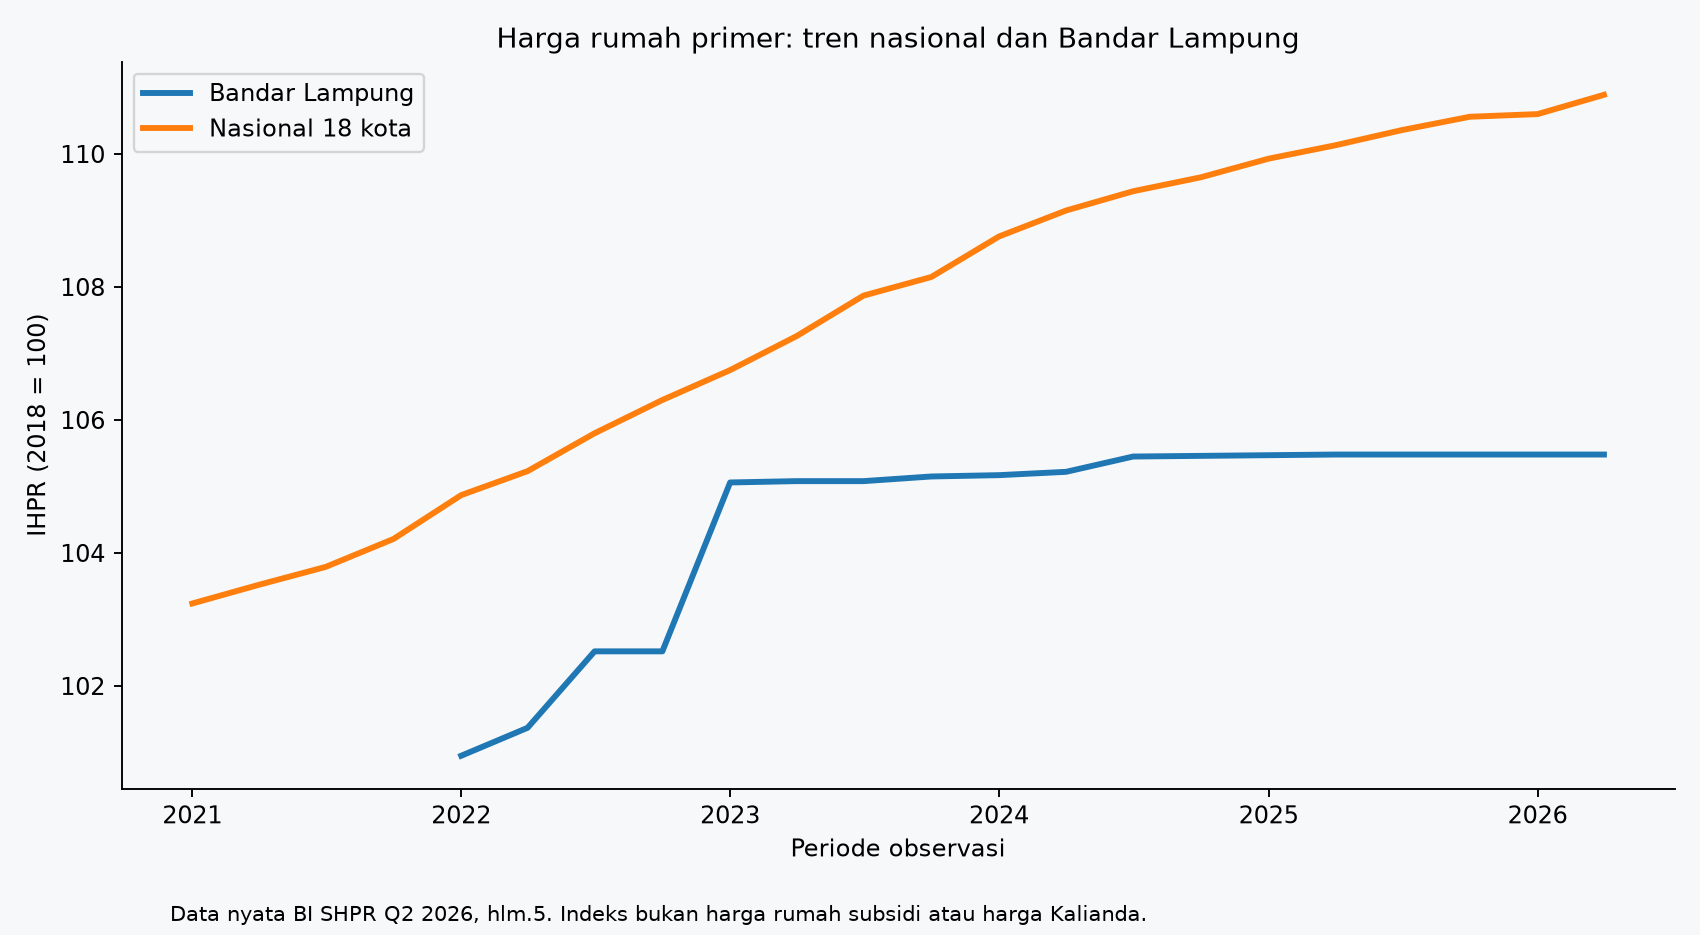

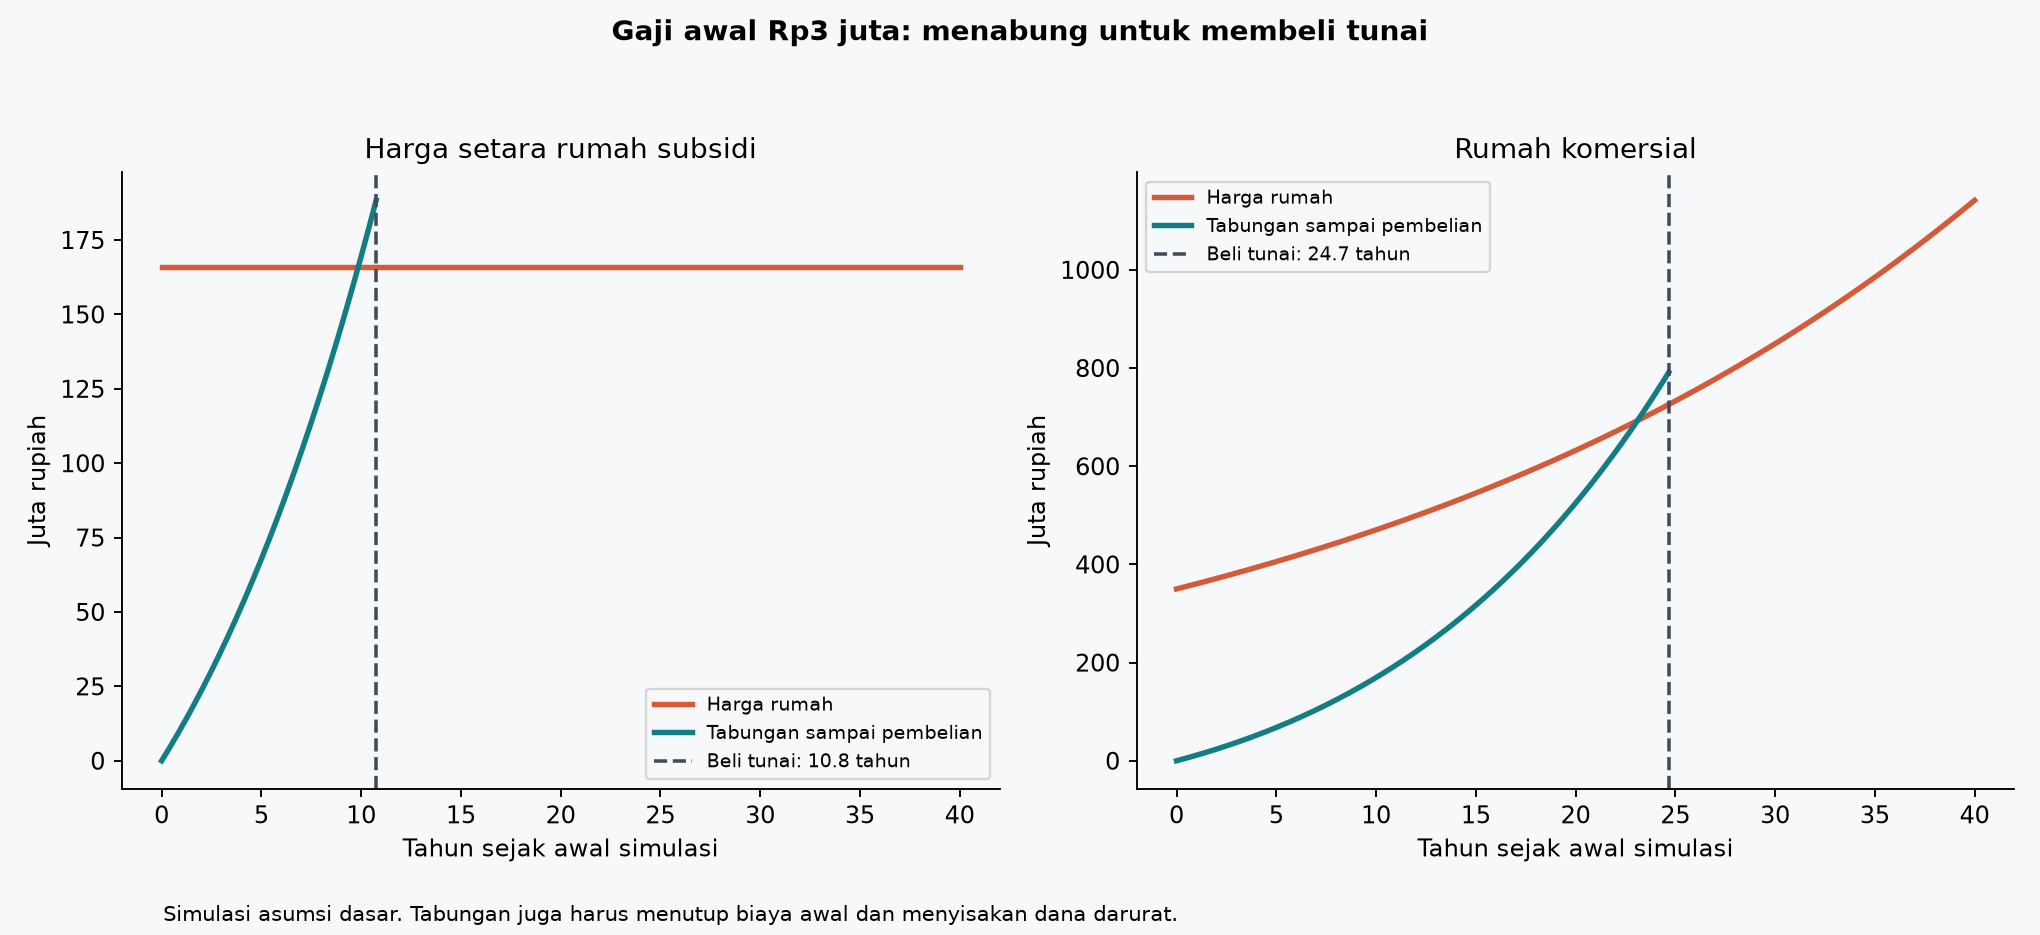

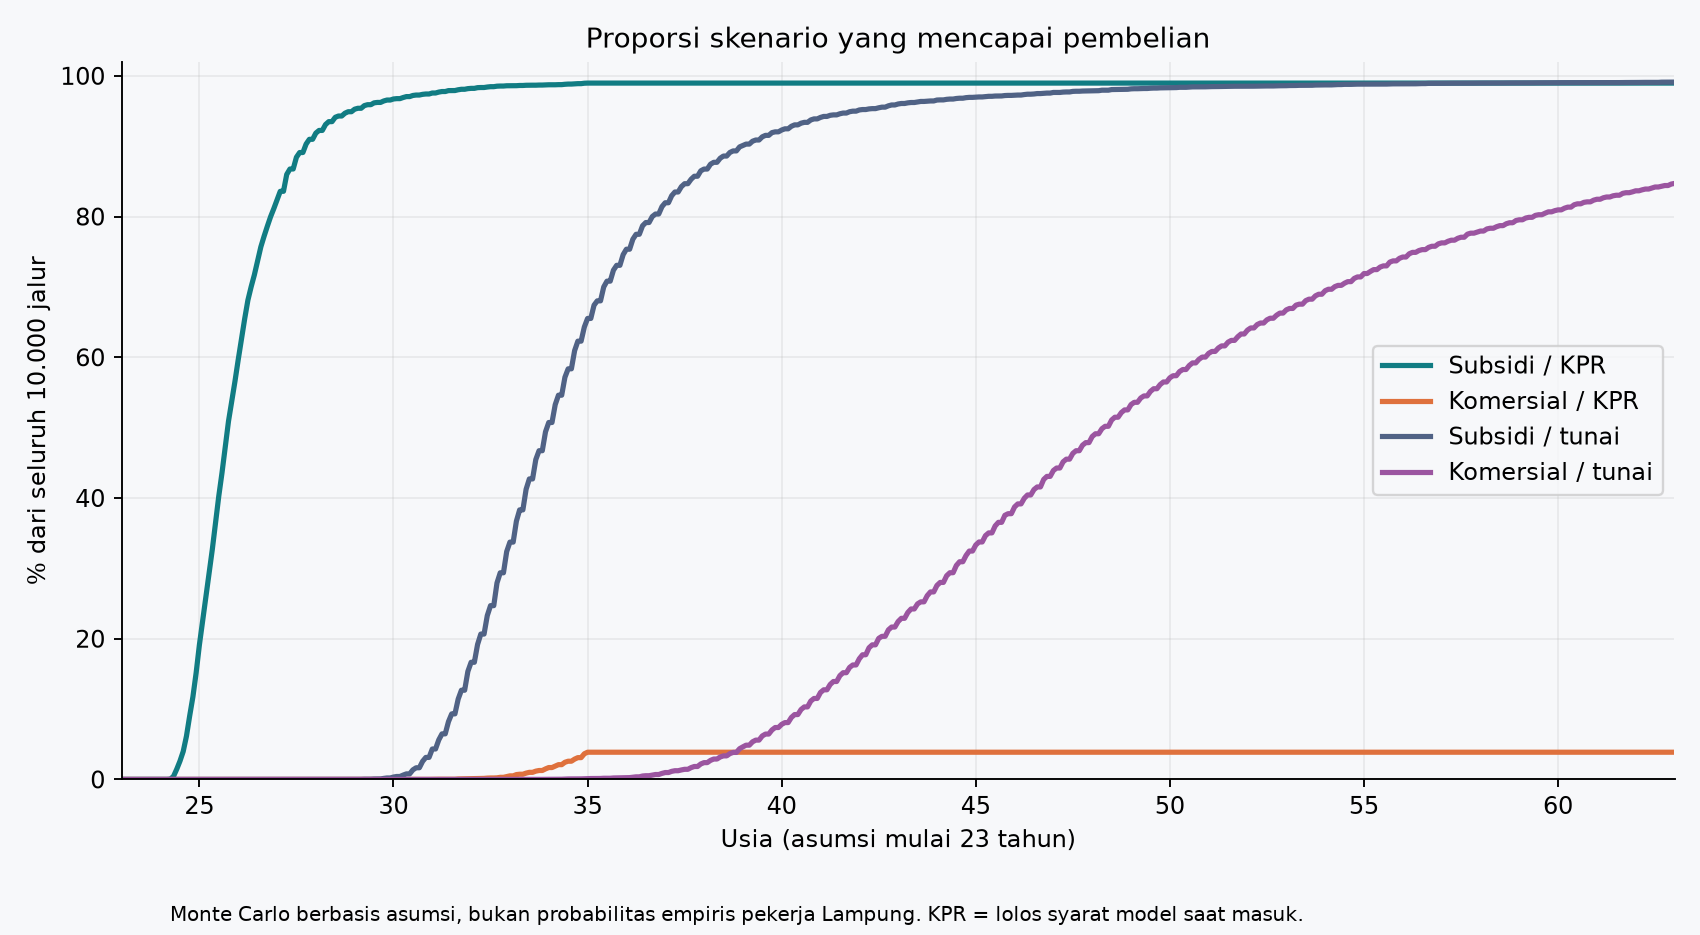

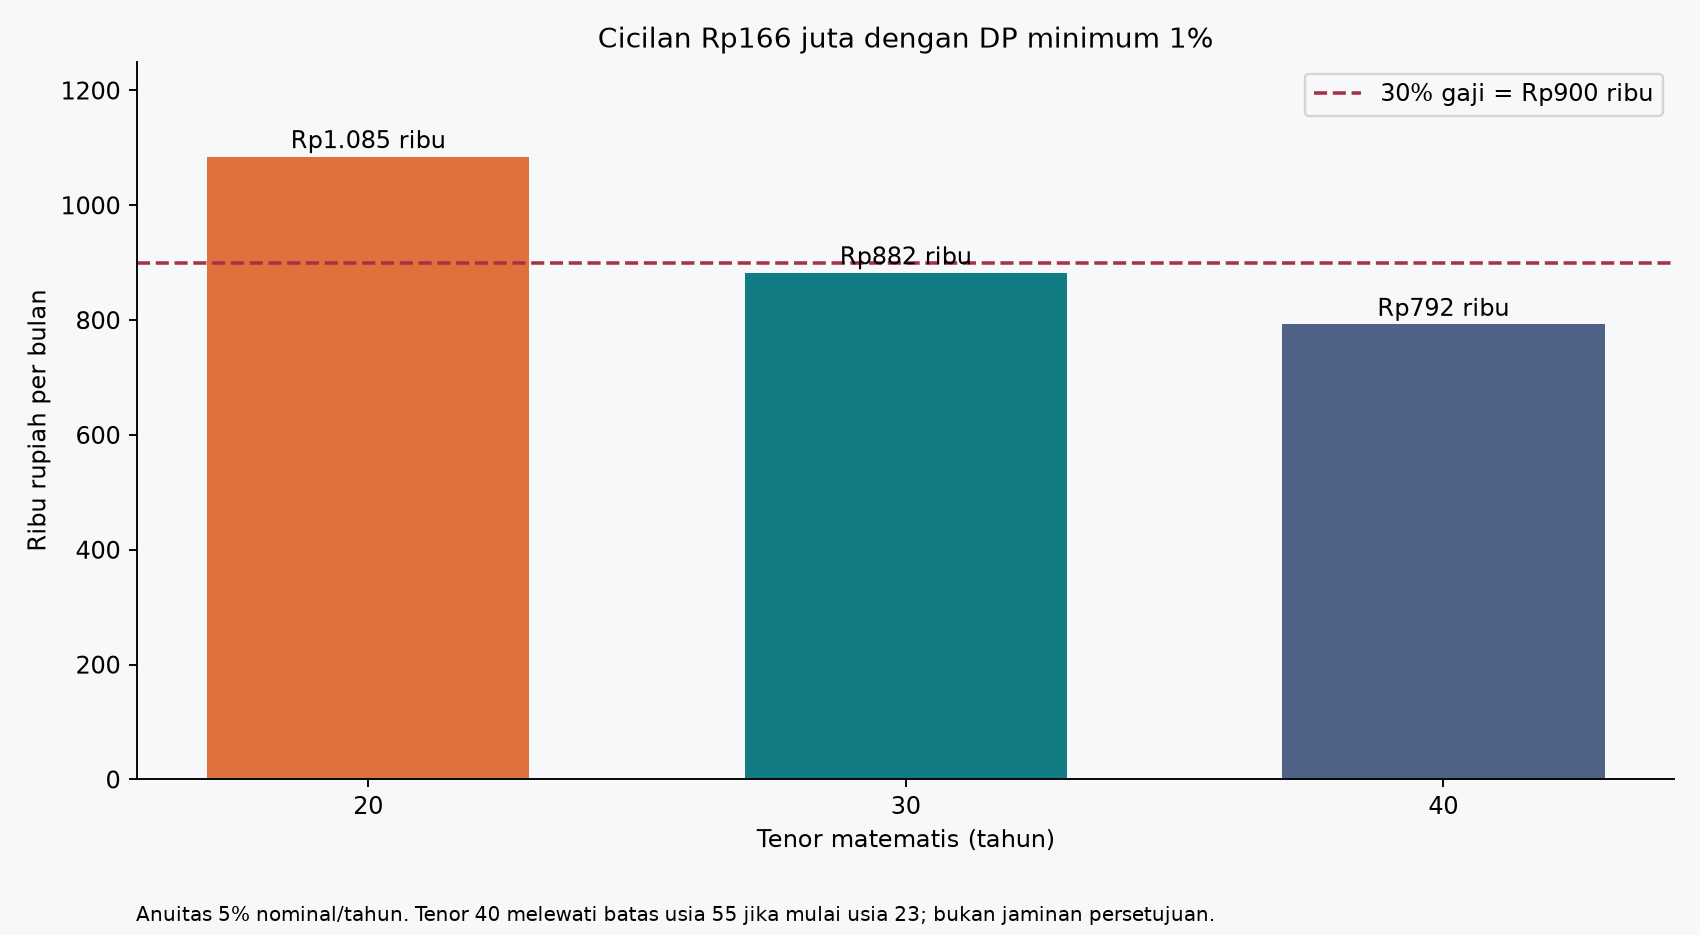

In [8]:
for filename in sorted(FIG.glob('*.png')):
    display(Image(filename=str(filename)))

## 7. Interpretasi dan batas

## Jawaban utama

Untuk profil contoh berusia 23 tahun, gaji bersih Rp3 juta dan biaya hidup Rp2,1 juta per bulan, skenario dasar mencapai syarat finansial KPR rumah Rp166 juta setelah **2 tahun 9 bulan**. Hasil ini mengasumsikan gaji naik 4% per tahun, biaya naik 3%, harga setara subsidi tetap, dan bunga anuitas nominal 5% selama 20 tahun.

DP aktual saat masuk sekitar **Rp15,05 juta**, karena tabungan yang tersedia dipakai untuk memperbesar DP. Cicilan awal sekitar **Rp996 ribu per bulan**, dengan biaya awal Rp4,98 juta dan dana darurat sekitar Rp13,67 juta tetap diperhitungkan. Usia masuk sekitar 25 tahun 9 bulan; pelunasan terjadwal pada usia 45 tahun 9 bulan.

| Alternatif | Waktu mencapai syarat pembelian | Usia saat membeli |
|---|---|---|
| KPR rumah subsidi, anuitas 20 tahun | 2 tahun 9 bulan | 25 tahun 9 bulan |
| Tunai rumah dengan harga setara subsidi | 10 tahun 9 bulan | 33 tahun 9 bulan |
| Tunai rumah komersial | 24 tahun 8 bulan | 47 tahun 8 bulan |
| KPR rumah komersial, tenor 20 tahun | Tidak tercapai dengan batas usia lunas 55 tahun | Kesempatan masuk berakhir pada usia 35 tahun |

Harga komersial awal Rp350 juta tumbuh menjadi sekitar Rp725,6 juta pada saat pembelian tunai. Jika batas usia lunas dalam skenario komersial diganti menjadi 65 tahun, syarat KPR tercapai setelah **19 tahun 10 bulan**. Artinya, hasil “tidak tercapai” bergantung pada ketentuan usia yang dipilih, bukan berarti mustahil seumur hidup.

Perbedaan bunga sangat berpengaruh: halaman Tapera yang tersimpan menulis “5% flat”. Bila benar-benar dihitung dengan metode flat, waktu KPR subsidi menjadi **4 tahun 5 bulan**, dibandingkan **2 tahun 9 bulan** dengan anuitas. Kedua perhitungan tersedia; angka anuitas tidak disajikan sebagai penafsiran pasti kontrak bank.



Baca laporan lengkap untuk audit sumber, asumsi, dan ketidaksesuaian tabel BPS. Model belum memasukkan kehilangan pekerjaan, penambahan tanggungan, perubahan keluarga, renovasi besar, atau perubahan aturan. Hasil adalah simulasi bersyarat, bukan ramalan resmi atau peluang seluruh pekerja Lampung.